# IOI and Colored Objects circuits in Qwen2.5, and do they behave like GPT-2's? (Colab, Hugging Face)

Living Science's IOI replication (Oct 2026) found Qwen2.5-0.5B solves IOI better than any GPT-2
(logit difference +5.06, 100% correct) but left open *how*: no circuit was extracted. This notebook
answers that and then reruns the exclusion follow-up on Qwen.

**Part A: find the circuits (IOI and Colored Objects) before testing anything.** No head lists exist
for Qwen, so they are discovered:
1. **Per-head ablation map**: each query head is mean-ablated alone; effect on the logit difference.
2. **Direct logit attribution (DLA)**: each head's direct push on correct − best wrong answer.
3. **Attention signatures**: from the final token to the answer, the distractors, the repeated item,
   the bound key; and from the repeated token back to its first mention (duplicate-token) or the token
   after it (induction).
4. **Faithfulness curve** on held-out prompts: keep the top-k heads, mean-ablate everything else;
   the circuit is the smallest k reaching `FAITH_TARGET` (0.8).
5. **Roles**. *Output heads* have a direct effect of at least 25% of the largest head's (and ≥ 2% of the
   clean logit difference), and are
   named by its sign and by where they look from the final token: **movers** (look at the answer, push
   it up), **negative movers** (look at the answer, push it down), **direct suppressors** (look at the
   repeated item / distractors and push them down, like GPT-2 Medium's 19.1), **distractor movers**
   (look at a distractor and push it up). *Selectors* have little direct effect, but ablating them
   changes where the output heads look; they are **suppressors** (look at the repeated item or
   distractors: IOI-style inhibition) or **promoters** (look at the answer or the bound key:
   Colored-Objects-style gatherers). **Duplicate/induction** heads look from the repeated token back to
   its first mention or the token after it. Roles are only assigned when the task is solved (clean
   logit difference ≥ 0.5).
6. **Checks**: necessity vs random layer-matched head sets, and IOI–CO overlap vs chance.

**Part B: the same tests as the GPT-2 follow-up, with the discovered groups.** Minimal pairs (flip /
no-repeat), DoubleIO/TripleIO analogues, three-entity chains, relation-only with 0–2 examples,
ablations (mean and resample), forced attention, per-head maps, plus Colored Objects: accuracy, the
Merullo repair with Qwen's own suppressors, and IOI–CO head overlap. Claim criteria are the corrected
ones (signed C2, C4 at the largest shot count, C6 by top-k overlap with a permutation null).

**Qwen specifics handled here**
- **Grouped-query attention**: 14 query heads share 2 key/value heads per layer (0.5B). Everything is
  done per *query* head: ablation and patching act on the head's output before `o_proj`, and forced
  attention rebuilds the head's output from the value vectors of its own KV group.
- **Digits are split into single tokens**, so Greater-Than and two-digit binding tasks don't apply;
  the unrelated-mechanism baseline is **sequence continuation** ("Monday, Tuesday, Wednesday," → Thursday).
- **Mean ablation is template-aware**: a head is replaced by its mean output at the same position over
  prompts with the same template and length (Wang et al.-style), not a global mean.

**Before running**
- Runtime → **T4 GPU** → Run all. Qwen2.5-0.5B is ungated; no token needed. Not timed on a GPU. My
  estimate is **30–75 min for 0.5B**; adding `Qwen/Qwen2.5-1.5B` to `MODELS` adds roughly 1.5–2.5 h.
  `QUICK = True` cuts this to roughly a third. Results are saved after each model.
- `TEST_MODE = True` runs a tiny Qwen2 model (same Hugging Face code) with a locally trained tokenizer,
  on CPU. It checks the code only; its numbers are meaningless. (If a file `test_tiny_qwen2.pt` is
  present, it loads those weights instead of random ones; the test harness used one trained on IOI.)
- The **sanity checks** cell runs on the real model first and stops the notebook if any hook is wrong.

In [ ]:
%pip install -q "transformers>=4.48" accelerate tokenizers

## Configuration

In [ ]:
MODELS = ["Qwen/Qwen2.5-0.5B"]          # add "Qwen/Qwen2.5-1.5B" for the scale comparison
TEST_MODE = False
QUICK = False

SEED = 0
BATCH = 32
N_PER = 150              # items per condition (twins share items)
N_DISC = 64              # discovery split; the next N_DISC prompts are the held-out split for faithfulness
N_RAND_SETS = 10         # random layer-matched head sets (core conditions)
SHOTS = [0, 1, 2]
K_GRID = [5, 10, 15, 20, 30, 40, 60]
FAITH_TARGET = 0.80
TOPK_OVERLAP = 15

ROLE = dict(out_rel=0.25,      # output head: |DLA| >= 25% of the largest |DLA| in the model ...
            out_abs=0.02,      # ... and >= 2% of the clean logit difference
            mediation=-0.03,   # ablating a selector must lower the movers' attention preference by >= 0.03
            dup=0.30, ind=0.30)  # attention from the repeated token to its first mention / the token after

TH = dict(norep_collapse=0.70, flip_drop=0.25, triple_hold=0.90, chain_gap=0.30,
          fewshot_margin=0.20, faith=FAITH_TARGET)
N_BOOT = 1000
OUT_DIR = "qwen_circuit_results"
SAVE_TO_DRIVE = False

if QUICK:
    N_PER, N_DISC, N_RAND_SETS, N_BOOT, K_GRID = 80, 40, 4, 300, [5, 10, 20, 40]
if TEST_MODE:
    MODELS = ["test/tiny-qwen2"]
    N_PER, N_DISC, N_RAND_SETS, N_BOOT, BATCH, K_GRID = 24, 10, 2, 50, 12, [3, 6, 12]

## Setup: model, tokenizer, hooks

In [ ]:
import os, re, json, math, random, time, gc
from collections import defaultdict
from contextlib import contextmanager
import numpy as np
import torch
import matplotlib.pyplot as plt
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer

torch.set_grad_enabled(False)
os.makedirs(OUT_DIR, exist_ok=True)
DEV = "cuda" if torch.cuda.is_available() and not TEST_MODE else "cpu"
print(f"torch {torch.__version__} | transformers {transformers.__version__} | device {DEV}")
_TV = tuple(int(x) for x in transformers.__version__.split(".")[:2])
DTYPE_KW = "dtype" if _TV >= (4, 56) else "torch_dtype"

model = tok = None
TEST_TOK = None
TEST_WEIGHTS = "test_tiny_qwen2.pt"      # TEST_MODE only


def build_test_tokenizer(corpus):
    """Byte-level BPE trained on this notebook's prompts, digits split like Qwen's tokenizer."""
    from tokenizers import Tokenizer, models, pre_tokenizers, trainers, decoders
    from transformers import PreTrainedTokenizerFast
    t = Tokenizer(models.BPE())
    t.pre_tokenizer = pre_tokenizers.Sequence([pre_tokenizers.Digits(individual_digits=True),
                                               pre_tokenizers.ByteLevel(add_prefix_space=False)])
    t.decoder = decoders.ByteLevel()
    tr = trainers.BpeTrainer(vocab_size=4000, min_frequency=1, special_tokens=["<|endoftext|>"],
                             initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
    t.train_from_iterator(corpus, tr)
    return PreTrainedTokenizerFast(tokenizer_object=t, eos_token="<|endoftext|>", pad_token="<|endoftext|>")


def load(name):
    global model, tok, LAYERS, NL, NH, NKV, HD, D, PAD_ID, EPS
    if model is not None:
        del model; gc.collect()
        if DEV == "cuda": torch.cuda.empty_cache()
    if TEST_MODE:
        from transformers import Qwen2Config, Qwen2ForCausalLM
        tok = TEST_TOK
        cfg = Qwen2Config(vocab_size=len(tok), hidden_size=96, intermediate_size=192, num_hidden_layers=8,
                          num_attention_heads=6, num_key_value_heads=2, max_position_embeddings=1024,
                          tie_word_embeddings=True, attn_implementation="eager")
        torch.manual_seed(SEED)
        model = Qwen2ForCausalLM(cfg)
        if os.path.exists(TEST_WEIGHTS):                           # a tiny model trained on IOI/CO by the test harness
            model.load_state_dict(torch.load(TEST_WEIGHTS, map_location="cpu"))
            print(f"TEST_MODE: loaded trained test weights from {TEST_WEIGHTS}")
        else:
            for n_, p in model.named_parameters():
                if "proj" in n_ and p.dim() == 2: p.data *= 3      # sharper attention so hooks are exercised
    else:
        tok = AutoTokenizer.from_pretrained(name)
        model = AutoModelForCausalLM.from_pretrained(name, attn_implementation="eager", **{DTYPE_KW: torch.float32})
    model.to(DEV).eval()
    for p in model.parameters():
        p.requires_grad_(False)
    c = model.config
    LAYERS = model.model.layers
    NL, NH, NKV, D = c.num_hidden_layers, c.num_attention_heads, c.num_key_value_heads, c.hidden_size
    HD = getattr(c, "head_dim", None) or D // NH
    EPS = c.rms_norm_eps
    PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id
    assert model.config._attn_implementation == "eager", "attention readouts need eager attention"
    print(f"loaded {name}: {NL} layers x {NH} query heads ({NKV} KV heads), head_dim {HD}, d_model {D}")


def encode(text):
    enc = tok(text, return_offsets_mapping=True, add_special_tokens=False)
    return list(enc["input_ids"]), list(enc["offset_mapping"])


def single_token(s):
    ids, _ = encode(s)
    return ids[0] if len(ids) == 1 else None


SETS = ["ref", "other", "subj", "bkey"]


def pad(batch):
    T = max(len(q["ids"]) for q in batch)
    toks = torch.full((len(batch), T), PAD_ID, dtype=torch.long)
    M = torch.zeros(len(batch), len(SETS), T)
    for i, q in enumerate(batch):
        toks[i, :len(q["ids"])] = torch.tensor(q["ids"])
        for s, name in enumerate(SETS):
            if q["sets"][name]:
                M[i, s, q["sets"][name]] = 1.0
    return toks.to(DEV), torch.tensor([q["last"] for q in batch], device=DEV), M.to(DEV)


@contextmanager
def hooked(handles):
    try:
        yield
    finally:
        for h in handles:
            h.remove()


def _by_layer(heads):
    d = defaultdict(list)
    for l, h in heads:
        d[l].append(h)
    return d


def run_batch(prompts, idx, ivs=(), attn=False, grab_z=False):
    """Right-padded batch (causal attention: real positions never see the padding). Returns final logits
    [B, V]; optionally final-position attention mass per set [B, L, H, S] and the full attention list;
    optionally each head's output at the final position [B, L, H, HD] and the final RMS scale [B]."""
    batch = [prompts[i] for i in idx]
    toks, lasts, M = pad(batch)
    B, T = toks.shape
    ar = torch.arange(B, device=DEV)
    ctx = dict(batch=batch, idx=idx, lasts=lasts, ar=ar, B=B, T=T, toks=toks)
    handles, zst = [], {}
    for iv in ivs:
        handles += iv(ctx)
    if grab_z:
        for l in range(NL):
            handles.append(LAYERS[l].self_attn.o_proj.register_forward_pre_hook(
                lambda m, a, l=l: zst.__setitem__(l, a[0].view(B, T, NH, HD)[ar, lasts].clone())))
        handles.append(model.model.norm.register_forward_pre_hook(
            lambda m, a: zst.__setitem__("rms", a[0][ar, lasts].pow(2).mean(-1).add(EPS).sqrt())))
    with hooked(handles):
        out = model.model(input_ids=toks, output_attentions=attn, use_cache=False)
    logits = model.lm_head(out.last_hidden_state[ar, lasts]).float()
    res = dict(logits=logits)
    if attn:
        res["mass"] = torch.stack([torch.einsum("bht,bst->bhs", A[ar, :, lasts, :].float(), M) for A in out.attentions], 1)
        res["attn"] = out.attentions
    if grab_z:
        res["z"] = torch.stack([zst[l] for l in range(NL)], 1)
        res["rms"] = zst["rms"]
    return res


def run(prompts, ivs=(), attn=False, bs=None):
    bs = bs or BATCH
    LG, MS = [], []
    for s in range(0, len(prompts), bs):
        r = run_batch(prompts, list(range(s, min(s + bs, len(prompts)))), ivs, attn=attn)
        LG.append(r["logits"].cpu())
        if attn:
            MS.append(r["mass"].cpu())
    return torch.cat(LG), (torch.cat(MS) if attn else None)


# ---- template-aware mean of every head's output -------------------------------------------------------
def bucket(q):
    m = q["meta"]
    return (len(q["ids"]), m.get("task"), m.get("variant"), m.get("tpl"), m.get("query"), m.get("n"))


def mean_z(prompts):
    """Per-bucket (same template and length) mean head output at each position, plus a global
    position-agnostic fallback for buckets with fewer than 2 prompts."""
    sums, cnt = {}, defaultdict(int)
    gsum, gcnt = torch.zeros(NL, NH, HD, device=DEV), 0.0
    for s in range(0, len(prompts), BATCH):
        batch = prompts[s:s + BATCH]
        toks, lasts, _ = pad(batch)
        B, T = toks.shape
        zs = {}
        hs = [LAYERS[l].self_attn.o_proj.register_forward_pre_hook(
            lambda m, a, l=l: zs.__setitem__(l, a[0].view(B, T, NH, HD))) for l in range(NL)]
        with hooked(hs):
            model.model(input_ids=toks, use_cache=False)
        Z = torch.stack([zs[l] for l in range(NL)], 0)          # [L, B, T, H, HD]
        for i, q in enumerate(batch):
            k, n = bucket(q), len(q["ids"])
            sums[k] = sums.get(k, 0) + Z[:, i, :n]
            cnt[k] += 1
            gsum += Z[:, i, :n].sum(1); gcnt += n
    MZ = {k: v / cnt[k] for k, v in sums.items() if cnt[k] >= 2}
    return dict(bucket=MZ, glob=gsum / gcnt)


def _mz_batch(MZ, batch, l, T):
    out = torch.empty(len(batch), T, NH, HD, device=DEV)
    for i, q in enumerate(batch):
        k, n = bucket(q), len(q["ids"])
        out[i, :n] = MZ["bucket"][k][l] if k in MZ["bucket"] else MZ["glob"][l][None]
        out[i, n:] = 0
    return out


def iv_ablate(heads, MZ):
    """Template-aware mean ablation of query heads at every position."""
    by_l = _by_layer(heads)
    def install(ctx):
        hs = []
        for l, hl in by_l.items():
            mz = _mz_batch(MZ, ctx["batch"], l, ctx["T"])[:, :, hl]
            def pre(m, a, hl=hl, mz=mz):
                z = a[0].view(ctx["B"], ctx["T"], NH, HD).clone()
                z[:, :, hl] = mz
                return (z.view(ctx["B"], ctx["T"], NH * HD),) + a[1:]
            hs.append(LAYERS[l].self_attn.o_proj.register_forward_pre_hook(pre))
        return hs
    return install


def iv_resample(heads, P, partner):
    """Resample ablation: heads take their output from a partner prompt with the same template and
    length (so positions align), at every position."""
    by_l = _by_layer(heads)
    def install(ctx):
        src = [P[partner[i]] for i in ctx["idx"]]
        toks, _, _ = pad(src)
        B, T = toks.shape
        zs = {}
        hs = [LAYERS[l].self_attn.o_proj.register_forward_pre_hook(
            lambda m, a, l=l: zs.__setitem__(l, a[0].view(B, T, NH, HD).clone())) for l in by_l]
        with hooked(hs):
            model.model(input_ids=toks, use_cache=False)
        out = []
        for l, hl in by_l.items():
            def pre(m, a, l=l, hl=hl):
                z = a[0].view(ctx["B"], ctx["T"], NH, HD).clone()
                z[:, :, hl] = zs[l][:, :, hl]
                return (z.view(ctx["B"], ctx["T"], NH * HD),) + a[1:]
            out.append(LAYERS[l].self_attn.o_proj.register_forward_pre_hook(pre))
        return out
    return install


def iv_force(heads, pos_fn):
    """Force query heads' attention from the final position to be uniform over pos_fn(q). With GQA the
    head's output is rebuilt from the value vectors of its own KV group: z = sum_t a_t v_t."""
    by_l = _by_layer(heads)
    def install(ctx):
        B, T = ctx["B"], ctx["T"]
        rows, use = torch.zeros(B, T, device=DEV), torch.zeros(B, dtype=torch.bool, device=DEV)
        for i, q in enumerate(ctx["batch"]):
            ps = sorted(set(pos_fn(q)))
            if ps:
                rows[i, ps] = 1.0 / len(ps); use[i] = True
        hs, vs = [], {}
        for l, hl in by_l.items():
            att = LAYERS[l].self_attn
            hs.append(att.v_proj.register_forward_hook(lambda m, i_, o, l=l: vs.__setitem__(l, o.view(B, T, NKV, HD))))
            def pre(m, a, l=l, hl=hl):
                z = a[0].view(B, T, NH, HD).clone()
                for h in hl:
                    new = torch.einsum("bt,btd->bd", rows, vs[l][:, :, h // (NH // NKV)])
                    z[ctx["ar"], ctx["lasts"], h] = torch.where(use[:, None], new, z[ctx["ar"], ctx["lasts"], h])
                return (z.view(B, T, NH * HD),) + a[1:]
            hs.append(att.o_proj.register_forward_pre_hook(pre))
        return hs
    return install


def boot_ci(x, seed=SEED):
    x = np.asarray(x, dtype=float); x = x[~np.isnan(x)]
    if len(x) == 0:
        return (np.nan, np.nan)
    r = np.random.default_rng(seed)
    m = [x[r.integers(0, len(x), len(x))].mean() for _ in range(N_BOOT)]
    return tuple(float(v) for v in np.percentile(m, [2.5, 97.5]))

torch 2.11.0+cu130 | transformers 5.18.0 | device cuda


## Prompts
Same designs as the GPT-2 follow-up, plus Colored Objects (Merullo one-shot format, demo colours and
objects disjoint from the test item) and the sequence-continuation baseline. Every candidate mention is
tagged so it maps to exactly one token; prompts where a tagged word splits are dropped, and twins are
kept only if all of an item's variants survive.

In [ ]:
NAMES = """Aaron Adam Alan Alex Alice Amy Andre Andrew Andy Anna Anthony Arthur Austin Blake Brandon Brian
Carter Charles Charlie Christian Clark Cole Connor Daniel David Dean Edward Emily Eric Eva Frank George Grace
Graham Grant Henry Ian Jack Jacob Jake James Jane Jason Jay Jessica John Jordan Joseph Justin Kate Kelly Kevin
Kyle Laura Leon Lewis Lisa Louis Luke Marco Marcus Maria Mark Martin Mary Max Michael Morgan Patrick Paul Peter
Rachel Richard Robert Rose Ruby Ryan Sarah Scott Sean Simon Steven Taylor Thomas Tyler Warren William""".split()
ANIMALS = ["cat", "dog", "bird", "fox", "cow", "horse", "pig", "sheep", "duck", "goat", "mouse", "rabbit"]
ITEMS = ["key", "coin", "ring", "pen", "cup", "book", "ball", "card", "stone", "watch", "phone", "spoon"]
FURNITURE = ["lamp", "chair", "table", "sofa", "desk", "bed", "clock", "plant", "shelf", "box", "mirror", "rug"]
VARS = ["x", "y", "z", "p", "q", "r", "m", "n", "k", "u", "v", "w"]
PLACES = ["store", "garden", "restaurant", "school", "hospital", "office", "house", "station"]
IOI_OBJECTS = ["ring", "kiss", "bone", "basketball", "computer", "necklace", "drink", "snack"]
CO_OBJECTS = ["pencil", "notebook", "pen", "cup", "plate", "jug", "mug", "puzzle", "textbook", "leash",
              "necklace", "bracelet", "bottle", "ball", "envelope", "lighter", "bowl"]
COLORS = ["red", "orange", "yellow", "green", "blue", "purple", "brown", "black"]
SEQS = {"weekdays": ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
        "months": ["January", "February", "March", "April", "May", "June", "July", "August", "September",
                   "October", "November", "December"],
        "numbers": ["one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten"]}
SEQ_PREFIX = ["Count:", "The list goes", "In order:", "She said", "Sequence:", "Next up:"]


class Builder:
    def __init__(self):
        self.text, self.marks = "", []

    def __call__(self, *pieces):
        for p in pieces:
            if isinstance(p, tuple):
                self.marks.append((len(self.text), len(self.text) + len(p[0]), p[1]))
                self.text += p[0]
            else:
                self.text += p
        return self


def fill(template, slots, prefix=""):
    b = Builder()(prefix)
    for part in re.split(r"(\{[A-Za-z]+\})", template):
        if part.startswith("{") and part.endswith("}"):
            b(slots[part[1:-1]])
        elif part:
            b(part)
    return b


def plain(slots):
    return {k: (v[0] if isinstance(v, tuple) else v) for k, v in slots.items()}


def art(w):
    return "an" if w[0] in "aeiou" else "a"


IOI_TEMPLATES = [
    "Then, {A} and {B} went to the {P}.{EX} {S} gave a {O} to",
    "After {A} and {B} went to the {P},{EX} {S} gave a {O} to",
    "Then, {A} and {B} had a lot of fun at the {P}.{EX} {S} gave a {O} to",
    "While {A} and {B} were working at the {P},{EX} {S} gave a {O} to",
    "Friends {A} and {B} found a {O} at the {P}.{EX} {S} gave it to",
]
EXCL = {
    "equality": dict(pool=VARS, ctx="We know that {A} = {B}", ex=[", and {Y} > 0", " and {Y} < 9"],
                     q=lambda x, v: ". Therefore, {S} " + ("≠" if v == "flip" else "="), flip=None),
    "inequality": dict(pool=VARS, ctx="We know that {A} < {B}", ex=[", and {Y} is positive", " and {Y} is small"],
                       q=lambda x, v: ". Equivalently, {S} " + ((">" if x else "<") if v != "flip" else ("<" if x else ">")),
                       flip=None),
    "spatial": dict(pool=FURNITURE, ctx="The {A} is to the left of the {B}.", ex=[" The {Y} is new.", " The {Y} is heavy."],
                    q=lambda x, v: " So the {S} is to the " + (("right" if x else "left") if v != "flip" else ("left" if x else "right")) + " of the",
                    flip=None),
    "elimination": dict(pool=ANIMALS, ctx="Either the {A} or the {B} broke the vase.", ex=[" The {Y} was nearby.", " The {Y} was hungry."],
                        q=lambda x, v: (" It was the {S}, so it was the" if v == "flip" else " It wasn't the {S}, so it was the"),
                        flip="x"),
    "set_removal": dict(pool=ITEMS, ctx="The box held a {A} and a {B}.", ex=[" The {Y} was shiny.", " The {Y} was old."],
                        q=lambda x, v: " I took out the {S}, so the box " + ("no longer holds the" if v == "flip" else "still holds the"),
                        flip="x"),
    "ioi": dict(pool=NAMES, ex=[" {Y} was happy.", " {Y} sat on a bench."], flip=None, no_flip=True),
}
VARIANTS = ["base", "flip", "norep", "double", "triple"]


def excl_item(task, rng):
    t = EXCL[task]
    A, B, Z = rng.sample(t["pool"], 3)
    x = rng.randrange(2); y = 1 - x
    X, Y = [A, B][x], [A, B][y]
    tpl_id = rng.randrange(len(IOI_TEMPLATES)) if task == "ioi" else 0
    P_, O_ = rng.choice(PLACES), rng.choice(IOI_OBJECTS)
    out = {}
    for v in VARIANTS:
        if v == "flip" and t.get("no_flip"):
            continue
        extra = {"double": t["ex"][0], "triple": t["ex"][0] + t["ex"][1]}.get(v, "")
        if task == "ioi":
            tpl = IOI_TEMPLATES[tpl_id].replace("{EX}", extra)
            if extra and "," in IOI_TEMPLATES[tpl_id].split("{EX}")[0][-1:]:
                tpl = IOI_TEMPLATES[tpl_id].replace(",{EX}", "." + extra)
        else:
            tpl = t["ctx"] + extra + t["q"](x, v)
        slots = {"A": (A, "c0"), "B": (B, "c1"), "Y": (Y, f"c{y}"), "P": P_, "O": O_,
                 "S": (Z, "s") if v == "norep" else (X, f"c{x}|s")}
        b = fill(tpl, slots)
        correct = y
        if v == "flip":
            correct = x if t["flip"] == "x" else None
        if v == "norep":
            correct = None
        out[v] = dict(text=b.text, marks=b.marks, out_words=[" " + A, " " + B], correct=correct, ref=y,
                      meta=dict(task=task, variant=v, x=x, tpl=tpl_id))
    return out


CHAINS = {
    "order": dict(pool=VARS, ctx="On the list, {A} comes right before {B}, and {B} comes right before {C}.",
                  qs=[(" So right after {A} comes", 1, "adjacent"), (" So two places after {A} comes", 2, "two-step"),
                      (" So right before {C} comes", 1, "adjacent"), (" So two places before {C} comes", 0, "two-step")]),
    "row": dict(pool=FURNITURE, ctx="The {A} is directly left of the {B}, and the {B} is directly left of the {C}.",
                qs=[(" So directly right of the {A} is the", 1, "adjacent"), (" So two places right of the {A} is the", 2, "two-step"),
                    (" So directly left of the {C} is the", 1, "adjacent"), (" So two places left of the {C} is the", 0, "two-step")]),
}


def chain_render(task, ents, qi):
    t = CHAINS[task]
    q, ans, kind = t["qs"][qi]
    return t["ctx"] + q, {"A": (ents[0], "c0"), "B": (ents[1], "c1"), "C": (ents[2], "c2")}, ans, kind


def relonly_render(task, ents, rng):
    if task == "inequality":
        q = rng.choice(["smaller", "larger"]); ans = 0 if q == "smaller" else 1
        tpl = "We know that {A} < {B}. So the " + q + " one is"
    else:
        rel, q = rng.choice(["left", "right"]), rng.choice(["left", "right"]); ans = 0 if rel == q else 1
        tpl = "The {A} is to the " + rel + " of the {B}. The one on the " + q + " is the"
    return tpl, {"A": (ents[0], "c0"), "B": (ents[1], "c1")}, ans


def with_shots(kind, task, rng, n_shot):
    k = 3 if kind == "chain" else 2
    pool = CHAINS[task]["pool"] if kind == "chain" else (VARS if task == "inequality" else FURNITURE)
    ents = rng.sample(pool, k * (n_shot + 1))
    demos = []
    for s in range(n_shot):
        e = ents[k * (s + 1): k * (s + 2)]
        if kind == "chain":
            tpl, slots, ans, _ = chain_render(task, e, rng.randrange(4))
        else:
            tpl, slots, ans = relonly_render(task, e, rng)
        demos.append(fill(tpl, plain(slots)).text + " " + e[ans] + "\n")
    test = ents[:k]
    if kind == "chain":
        tpl, slots, ans, qk = chain_render(task, test, rng.randrange(4))
    else:
        (tpl, slots, ans), qk = relonly_render(task, test, rng), None
    b = fill(tpl, slots, prefix="".join(demos))
    return dict(text=b.text, marks=b.marks, out_words=[" " + e for e in test], correct=ans, ref=ans,
                meta=dict(task=task, shots=n_shot, query=qk))


def co_item(rng, n):
    """Merullo et al. one-shot Colored Objects; the demo's colours and objects are disjoint from the test's."""
    cols, objs = rng.sample(COLORS, n), rng.sample(CO_OBJECTS, n)
    dcols = rng.sample([c for c in COLORS if c not in cols], n)
    dobjs = rng.sample([o for o in CO_OBJECTS if o not in objs], n)
    b = Builder()
    def example(cs, os_, qi, tag):
        b(f"Q: On the {rng.choice(['table', 'desk', 'floor'])}, {rng.choice(['there is', 'you see', 'I see'])} ")
        for i in range(n):
            if i:
                b(" and " if i == n - 1 else ", ")
            b(f"{art(cs[i])} ", (cs[i], f"c{i}") if tag else cs[i], " ", (os_[i], f"k{i}") if tag else os_[i])
        b(". What color is the ", (os_[qi], "s") if tag else os_[qi], "?\nA:")
    dq = rng.randrange(n)
    example(dcols, dobjs, dq, False); b(" " + dcols[dq].capitalize() + "\n")
    a = rng.randrange(n)
    example(cols, objs, a, True)
    return dict(text=b.text, marks=b.marks, out_words=[" " + c.capitalize() for c in cols], correct=a, ref=a,
                meta=dict(task=f"co{n}", n=n))


def seq_item(rng, seq_out):
    """Unrelated-mechanism baseline: continue a known sequence (no repeated tokens)."""
    cat = rng.choice(list(SEQ_OUT_WORDS))
    items = SEQS[cat]
    L = rng.choice([3, 4])
    s = rng.randrange(0, len(items) - L)
    b = Builder()(rng.choice(SEQ_PREFIX))
    for i, w in enumerate(items[s:s + L]):
        b(" " if i == 0 else ", ", (w, f"o{i}"))
    b(",")
    nxt = items[s + L]
    outs = SEQ_OUT_WORDS[cat]
    return dict(text=b.text, marks=b.marks, out_words=[" " + w for w in outs], correct=None, ref=None,
                correct_set=[w == nxt for w in outs], meta=dict(task=f"seq-{cat}", n=L))


SEQ_OUT_WORDS = {}

In [ ]:
def overlap(offs, s, e):
    return [k for k, (a, b) in enumerate(offs) if b > a and a < e and b > s]


def induction_pred(t):
    L = len(t)
    for k in range(min(8, L - 1), 0, -1):
        suf = t[L - k:]
        for i in range(L - 2, k - 2, -1):
            if t[i - k + 1:i + 1] == suf:
                return t[i + 1]
    return None


def prepare(raw):
    ids, offs = encode(raw["text"])
    out_ids = [single_token(w) for w in raw["out_words"]]
    if any(t is None for t in out_ids) or len(set(out_ids)) != len(out_ids):
        return None
    pos = defaultdict(list)
    for s, e, lab in raw["marks"]:
        ov = overlap(offs, s, e)
        if len(ov) != 1:
            return None
        for part in lab.split("|"):
            pos[part].append(ov[0])
    n = len(out_ids)
    q = dict(raw, ids=ids, last=len(ids) - 1, out_ids=out_ids, n=n)
    q["meta"] = dict(raw["meta"], n=n)
    if "correct_set" in raw:
        if all(raw["correct_set"]) or not any(raw["correct_set"]):
            return None
        q.update(cand_pos=[], counts=[], least=None, H={}, dup_src=None, dup_tgt=None,
                 sets=dict(ref=[], other=[p for k_, v in pos.items() for p in v], subj=[], bkey=[]))
        return q
    cand_pos = [pos.get(f"c{k}", []) for k in range(n)]
    counts = [len(p) for p in cand_pos]
    ref = raw["ref"]
    least = int(np.argmin(counts)) if n > 1 and sorted(counts)[0] < sorted(counts)[1] else None
    subj = pos.get("s", [])
    dup_src = subj[0] if subj else None
    dup_tgt = None
    if dup_src is not None:                          # earliest earlier occurrence of the same token
        prev = [i for i in range(dup_src) if ids[i] == ids[dup_src]]
        dup_tgt = prev[0] if prev else None
    q.update(cand_pos=cand_pos, counts=counts, least=least, dup_src=dup_src, dup_tgt=dup_tgt,
             sets=dict(ref=cand_pos[ref], other=[p for k in range(n) if k != ref for p in cand_pos[k]],
                       subj=subj, bkey=pos.get(f"k{ref}", [])))
    H = {"first": 0, "last-mentioned": int(np.argmax([max(p) if p else -1 for p in cand_pos]))}
    if least is not None:
        H["fewest mentions"] = least
    if n == 2 and subj and any(subj[0] in cand_pos[k] for k in range(2)):
        H["not the query subject"] = next(1 - k for k in range(2) if subj[0] in cand_pos[k])
    ind = induction_pred(ids)
    if ind in out_ids:
        H["induction"] = out_ids.index(ind)
    q["H"] = H
    return q


def build_all(rng):
    global SEQ_OUT_WORDS
    SEQ_OUT_WORDS = {c: [w for w in ws if single_token(" " + w) is not None] for c, ws in SEQS.items()}
    SEQ_OUT_WORDS = {c: ws for c, ws in SEQ_OUT_WORDS.items() if len(ws) == len(SEQS[c])}   # only fully single-token sequences
    C = {}
    def collect(gen, n, kind, **kw):
        P, seen, tries = [], set(), 0
        while len(P) < n and tries < n * 30:
            tries += 1
            q = prepare(gen())
            if q and q["text"] not in seen:
                seen.add(q["text"]); P.append(q)
        return dict(kind=kind, P=P, **kw)
    for task in EXCL:
        items, tries = [], 0
        while len(items) < N_PER + (N_DISC if task == "ioi" else 0) and tries < N_PER * 30:
            tries += 1
            vs = {v: prepare(r) for v, r in excl_item(task, rng).items()}
            if all(vs.values()):
                items.append(vs)
        for v in items[0]:
            C[f"{task}/{v}"] = dict(kind="excl", task=task, variant=v, P=[it[v] for it in items])
    for n in [2, 3]:
        C[f"co/{n}"] = collect(lambda: co_item(rng, n), N_PER + (N_DISC if n == 3 else 0), "co", task=f"co{n}")
    for task in CHAINS:
        for s in SHOTS:
            C[f"chain-{task}/{s}-shot"] = collect(lambda: with_shots("chain", task, rng, s), N_PER, "chain", task=task, shots=s)
    for task in ["inequality", "spatial"]:
        for s in SHOTS:
            C[f"relation-only-{task}/{s}-shot"] = collect(lambda: with_shots("relonly", task, rng, s), N_PER, "relonly", task=task, shots=s)
    if SEQ_OUT_WORDS:
        C["REF sequence"] = collect(lambda: seq_item(rng, SEQ_OUT_WORDS), N_PER, "seq", task="sequence")
    for c in C.values():
        P = c["P"]; b = defaultdict(list)
        for i, q in enumerate(P):
            b[bucket(q)].append(i)
        partner = list(range(len(P)))
        r = random.Random(SEED)
        for idx in b.values():
            if len(idx) > 1:
                r.shuffle(idx)
                for a_, b_ in zip(idx, idx[1:] + idx[:1]):
                    partner[a_] = b_
        c["partner"] = partner
        c["resampled_frac"] = float(np.mean([partner[i] != i for i in range(len(P))])) if P else 0.0
    return C


def corpus_for_test_tokenizer(rng):
    """Raw prompt text from every generator (no tokenizer needed), to train the TEST_MODE tokenizer."""
    global SEQ_OUT_WORDS
    SEQ_OUT_WORDS = dict(SEQS)
    texts = []
    for _ in range(400):
        for task in EXCL:
            texts += [r["text"] + r["out_words"][0] for r in excl_item(task, rng).values()]
        texts += [co_item(rng, 2)["text"], co_item(rng, 3)["text"] + " Blue Red Green Yellow Orange Purple Brown Black"]
        for task in CHAINS:
            texts.append(with_shots("chain", task, rng, 2)["text"])
        texts += [with_shots("relonly", t, rng, 2)["text"] for t in ["inequality", "spatial"]]
        texts.append(seq_item(rng, SEQS)["text"] + " " + " ".join(sum(SEQS.values(), [])))
    texts.append(" ".join(" " + w for w in NAMES + ANIMALS + ITEMS + FURNITURE + VARS + COLORS + CO_OBJECTS))
    return texts

## Metrics shared by all parts
- **LD** (logit difference) = logit(correct) − max logit(wrong candidates); for the sequence baseline,
  max over correct continuations − max over the rest.
- **ref-pref** = logit(ref) − max logit(other candidates), where *ref* is the answer the exclusion rule
  gives in the base twin. Defined for every variant, so twins compare directly.

In [ ]:
def scores(c, LG):
    P = c["P"]
    if c["kind"] == "seq":
        ld, acc = [], []
        for q, lg in zip(P, LG):
            v = lg[q["out_ids"]]
            m = torch.tensor(q["correct_set"])
            ld.append((v[m].max() - v[~m].max()).item()); acc.append(float(m[int(v.argmax())]))
        ld = np.array(ld)
        return dict(ref_pref=ld, ld=ld, acc=np.array(acc), choice=np.zeros(len(P), int), full=np.full(len(P), np.nan))
    choice = np.array([int(lg[q["out_ids"]].argmax()) for q, lg in zip(P, LG)])
    ref_pref = np.array([(lg[q["out_ids"][q["ref"]]] - max(lg[q["out_ids"][k]] for k in range(q["n"]) if k != q["ref"])).item()
                         for q, lg in zip(P, LG)])
    ld = np.array([(lg[q["out_ids"][q["correct"]]] - max(lg[q["out_ids"][k]] for k in range(q["n"]) if k != q["correct"])).item()
                   if q["correct"] is not None else np.nan for q, lg in zip(P, LG)])
    acc = np.array([float(ch == q["correct"]) if q["correct"] is not None else np.nan for q, ch in zip(P, choice)])
    full = np.array([float(lg.argmax().item() == q["out_ids"][q["correct"]]) if q["correct"] is not None else np.nan
                     for q, lg in zip(P, LG)])
    return dict(ref_pref=ref_pref, ld=ld, acc=acc, choice=choice, full=full)


def sub(c, P):
    d = dict(c); d["P"] = P
    return d

## Sanity checks (run on every model before any analysis)
1. Final logits computed from the last hidden state equal the model's own logits.
2. Resample ablation with each prompt as its own partner changes nothing.
3. Forced attention with each head's **own** attention row changes nothing (checks the value
   reconstruction and the GQA head → KV-group mapping).
4. Head outputs projected through their slice of `o_proj` sum to `o_proj`'s output (checks DLA slicing).
5. Mean ablation with a single-prompt "mean" (the prompt's own outputs) changes nothing.

In [ ]:
def sanity_checks(P):
    P = P[:6]
    toks, lasts, _ = pad(P)
    ar = torch.arange(len(P), device=DEV)
    ok = {}
    full = model(input_ids=toks, use_cache=False).logits[ar, lasts].float()
    base = run_batch(P, list(range(len(P))))["logits"]
    ok["1 logits path"] = (full - base).abs().max().item()
    heads = [(l, h) for l in range(NL) for h in range(0, NH, max(1, NH // 3))]
    r2 = run_batch(P, list(range(len(P))), [iv_resample(heads, P, list(range(len(P))))])["logits"]
    ok["2 resample with self"] = (r2 - base).abs().max().item()
    out = run_batch(P, list(range(len(P))), attn=True)
    L0 = NL // 2
    rows = out["attn"][L0][ar, :, lasts, :]            # [B, H, T] real attention rows from the last position
    def iv_own(ctx):
        B, T = ctx["B"], ctx["T"]
        vs = {}
        att = LAYERS[L0].self_attn
        h1 = att.v_proj.register_forward_hook(lambda m, i_, o: vs.__setitem__("v", o.view(B, T, NKV, HD)))
        def pre(m, a):
            z = a[0].view(B, T, NH, HD).clone()
            for h in range(NH):
                z[ctx["ar"], ctx["lasts"], h] = torch.einsum("bt,btd->bd", rows[:, h, :T], vs["v"][:, :, h // (NH // NKV)])
            return (z.view(B, T, NH * HD),) + a[1:]
        return [h1, att.o_proj.register_forward_pre_hook(pre)]
    r3 = run_batch(P, list(range(len(P))), [iv_own])["logits"]
    ok["3 forced attention = own attention"] = (r3 - base).abs().max().item()
    zs = {}
    att = LAYERS[L0].self_attn
    h1 = att.o_proj.register_forward_pre_hook(lambda m, a: zs.__setitem__("z", a[0]))
    h2 = att.o_proj.register_forward_hook(lambda m, i_, o: zs.__setitem__("o", o))
    with hooked([h1, h2]):
        model.model(input_ids=toks, use_cache=False)
    z = zs["z"].view(len(P), -1, NH, HD)
    W = att.o_proj.weight
    recon = sum(z[:, :, h] @ W[:, h * HD:(h + 1) * HD].T for h in range(NH)) + (att.o_proj.bias if att.o_proj.bias is not None else 0)
    ok["4 per-head o_proj slices"] = (recon - zs["o"]).abs().max().item()
    one = [P[0]]
    MZ1 = mean_z(one * 2)                               # two copies of one prompt: its mean is itself
    r5 = run_batch(one, [0], [iv_ablate(heads, MZ1)])["logits"]
    ok["5 mean ablation with own mean"] = (r5 - base[:1]).abs().max().item()
    tol = 1e-3 * max(1.0, base.abs().max().item())
    for k, v in ok.items():
        print(f"  {k:38s} max |diff| {v:.2e}  {'ok' if v < tol else 'FAIL'}")
    assert all(v < tol for v in ok.values()), "a hook check failed; do not trust the analyses"

## Part A: circuit discovery for IOI and Colored Objects
Discovery uses the first `N_DISC` prompts of the task; faithfulness is measured on the next `N_DISC`
(held out). For each head:
- **effect**: drop in mean LD when the head alone is mean-ablated, as a fraction of the clean LD;
- **DLA**: the head's direct contribution to LD at the final position (its output through its slice of
  `o_proj`, divided by the final RMS, times the final norm weight, dotted with W_U[correct] − W_U[best wrong]);
- **attention** from the final position to: the answer, the distractors, the query subject (the
  repeated name in IOI, the queried object in CO), the bound key (CO); and from the query subject back
  to its first occurrence (**dup**) and to the token after it (**ind**).

**Circuit** = top-k heads by |effect| ∪ movers ∪ negative movers; k is the smallest value in `K_GRID`
whose held-out faithfulness (circuit kept, every other head mean-ablated; clean LD = 1) lies in
[`FAITH_TARGET`, 1.25]. If none does, the k closest to 1 is used and the card says so.

In [ ]:
def dla_and_signatures(c, P):
    U = model.lm_head.weight
    g = model.model.norm.weight
    Wo = [LAYERS[l].self_attn.o_proj.weight for l in range(NL)]
    DLA = torch.zeros(NL, NH)
    SIG = {k: torch.zeros(NL, NH) for k in ["ans", "dist", "subj", "bkey", "dup", "ind"]}
    nd = torch.zeros(1)
    for s in range(0, len(P), BATCH):
        idx = list(range(s, min(s + BATCH, len(P))))
        r = run_batch(P, idx, attn=True, grab_z=True)
        batch = [P[i] for i in idx]
        lg = r["logits"]
        for j, q in enumerate(batch):
            if c["kind"] == "seq":
                v = lg[j, q["out_ids"]]; m = torch.tensor(q["correct_set"], device=DEV)
                a = q["out_ids"][int(torch.where(m, v, -1e9).argmax())]; b = q["out_ids"][int(torch.where(~m, v, -1e9).argmax())]
            else:
                a = q["out_ids"][q["correct"]]
                b = max((q["out_ids"][k] for k in range(q["n"]) if k != q["correct"]), key=lambda t: lg[j, t].item())
            u = (U[a] - U[b]) * g / r["rms"][j]                                   # [D]
            for l in range(NL):
                w = (Wo[l].view(D, NH, HD) * u[:, None, None]).sum(0)              # [H, HD]: u read back through each head's o_proj slice
                DLA[l] += (r["z"][j, l] * w).sum(-1).float().cpu()
        mass = r["mass"].cpu()                                                  # [B, L, H, S]
        SIG["ans"] += mass[..., 0].sum(0); SIG["dist"] += mass[..., 1].sum(0)
        SIG["subj"] += mass[..., 2].sum(0); SIG["bkey"] += mass[..., 3].sum(0)
        for j, q in enumerate(batch):
            if q["dup_src"] is not None and q["dup_tgt"] is not None:
                for l in range(NL):
                    A = r["attn"][l][j]
                    SIG["dup"][l] += A[:, q["dup_src"], q["dup_tgt"]].float().cpu()
                    if q["dup_tgt"] + 1 < q["dup_src"]:
                        SIG["ind"][l] += A[:, q["dup_src"], q["dup_tgt"] + 1].float().cpu()
                nd += 1
    n = len(P)
    out = {k: (v / n if k not in ("dup", "ind") else v / max(nd.item(), 1)).numpy() for k, v in SIG.items()}
    out["dla"] = (DLA / n).numpy()
    return out


def head_effects(c, P, MZ):
    base = scores(sub(c, P), run(P)[0])["ref_pref" if c["kind"] != "seq" else "ld"].mean()
    E = np.zeros((NL, NH))
    for l in range(NL):
        for h in range(NH):
            s = scores(sub(c, P), run(P, [iv_ablate([(l, h)], MZ)])[0])
            E[l, h] = (base - (s["ld"] if c["kind"] == "seq" else s["ref_pref"]).mean()) / (abs(base) + 1e-6)
    return E, float(base)


def faithfulness(c, P, heads, MZ):
    keep = set(heads)
    rest = [(l, h) for l in range(NL) for h in range(NH) if (l, h) not in keep]
    clean = scores(sub(c, P), run(P)[0])["ld"].mean()
    circ = scores(sub(c, P), run(P, [iv_ablate(rest, MZ)])[0])["ld"].mean() if rest else clean
    return float(circ / clean) if abs(clean) > 1e-6 else np.nan


def pick_head(r, l, exclude):
    """A random head from layer l not in `exclude`; if the layer is exhausted, from the nearest layer that isn't."""
    for d in range(NL):
        for L in sorted({l - d, l + d}):
            if 0 <= L < NL:
                free = [(L, h) for h in range(NH) if (L, h) not in exclude]
                if free:
                    return r.choice(free)
    raise ValueError("no free heads left")


def top_heads(E, k):
    return [(int(i // NH), int(i % NH)) for i in np.argsort(-np.abs(E).ravel())[:k]]


def mover_pref(mass, movers):
    """Movers' mean attention preference (answer minus distractors) from the final position."""
    return float(torch.stack([mass[:, l, h, 0] - mass[:, l, h, 1] for l, h in movers]).mean()) if movers else np.nan


def routing_score(mass, outs):
    """How well the output heads attend where their role says: movers to the answer, direct suppressors
    to the distractors (mean attention preference, final position)."""
    parts = []
    if outs.get("mover"):
        parts.append(mover_pref(mass, outs["mover"]))
    if outs.get("direct suppressor"):
        parts.append(-mover_pref(mass, outs["direct suppressor"]))
    return float(np.mean(parts)) if parts else np.nan


def discover(name, c):
    P_all = c["P"]
    Pd, Ph = P_all[:N_DISC], P_all[N_DISC:2 * N_DISC] or P_all[:N_DISC]
    t0 = time.time()
    MZd, MZh = mean_z(Pd), mean_z(Ph)
    sig = dla_and_signatures(c, Pd)
    E, base = head_effects(c, Pd, MZd)
    ld_clean = float(scores(sub(c, Pd), run(Pd)[0])["ld"].mean())
    solved = ld_clean >= 0.5
    dla, a_ans, a_dst = sig["dla"], sig["ans"], sig["dist"]
    thr = max(ROLE["out_rel"] * np.abs(dla).max(), ROLE["out_abs"] * abs(ld_clean))
    # output heads, by the sign of their direct effect and what they attend to from the final token
    outs = defaultdict(list)
    if solved:
        for l in range(NL):
            for h in range(NH):
                if abs(dla[l, h]) < thr:
                    continue
                to_ans = a_ans[l, h] > a_dst[l, h]
                role = ("mover" if to_ans else "direct suppressor") if dla[l, h] > 0 else ("neg mover" if to_ans else "distractor mover")
                outs[role].append((l, h))
    out_heads = {hd for v in outs.values() for hd in v}
    curve = {}
    for k in K_GRID:
        heads = sorted(set(top_heads(E, k)) | out_heads)
        curve[k] = dict(n_heads=len(heads), faith=faithfulness(c, Ph, heads, MZh))
    good = [k for k in K_GRID if FAITH_TARGET <= curve[k]["faith"] <= 2 - FAITH_TARGET + 0.05]
    k_star = good[0] if good else min(K_GRID, key=lambda k: abs(curve[k]["faith"] - 1))
    circuit = sorted(set(top_heads(E, k_star)) | out_heads)
    roles, med = {}, {}
    if solved:
        _, mass0 = run(Pd, attn=True)
        r0 = routing_score(mass0, outs)
        last_out = max([l for l, _ in out_heads], default=NL)
        for hd in circuit:
            l, h = hd
            for role, hs in outs.items():
                if hd in hs:
                    roles[hd] = role
            if hd in roles:
                continue
            if l < last_out and not np.isnan(r0):
                _, m1 = run(Pd, [iv_ablate([hd], MZd)], attn=True)
                med[hd] = routing_score(m1, outs) - r0
            is_dup = sig["dup"][l, h] >= ROLE["dup"] or sig["ind"][l, h] >= ROLE["ind"]
            end_mass = a_ans[l, h] + a_dst[l, h] + sig["bkey"][l, h]
            if is_dup and end_mass < 0.2:          # reads the repeat at its own position, not from the final token
                roles[hd] = "dup/induction"
            elif med.get(hd, 0) <= ROLE["mediation"]:
                supp = sig["subj"][l, h] + a_dst[l, h] >= a_ans[l, h] + sig["bkey"][l, h]
                roles[hd] = "suppressor" if supp else "promoter"
            elif is_dup:
                roles[hd] = "dup/induction"
            else:
                roles[hd] = "other"
    else:
        roles = {hd: "unassigned (task not solved)" for hd in circuit}
    MZf = mean_z(P_all[:2 * N_DISC])
    Pn = P_all[:2 * N_DISC]
    cl = scores(sub(c, Pn), run(Pn)[0])["ld"].mean()
    nec = cl - scores(sub(c, Pn), run(Pn, [iv_ablate(circuit, MZf)])[0])["ld"].mean()
    rng_ = random.Random(SEED)
    rd = []
    for _ in range(N_RAND_SETS):
        rs = []
        for l, _h in circuit:
            rs.append(pick_head(rng_, l, set(circuit) | set(rs)))
        rd.append(cl - scores(sub(c, Pn), run(Pn, [iv_ablate(rs, MZf)])[0])["ld"].mean())
    out = dict(E=E, base=base, ld_clean=ld_clean, solved=solved, sig=sig, outputs={k: v for k, v in outs.items()},
               movers=outs.get("mover", []), curve=curve, k=k_star, circuit=circuit, roles=roles, mediation=med,
               necessity=float(nec), rand_necessity=[float(x) for x in rd], faith=curve[k_star]["faith"],
               minutes=(time.time() - t0) / 60)
    print(f"  {name}: clean LD {ld_clean:+.2f}{'' if solved else ' (NOT SOLVED: roles skipped, ratios unreliable)'}; faithfulness by k: "
          + ", ".join(f"{k}:{v['faith']:.2f}({v['n_heads']})" for k, v in curve.items())
          + f"; chosen k={k_star} -> {len(circuit)} heads, faith {out['faith']:.2f}"
          + ("" if good else " (target not reached: closest to 1)")
          + f"; necessity {nec:+.2f} vs random max {max(rd) if rd else float('nan'):+.2f}  [{out['minutes']:.1f} min]")
    return out


def circuit_card(name, d):
    print(f"\n{name}: {len(d['circuit'])} heads, held-out faithfulness {d['faith']:.2f} (target {FAITH_TARGET})")
    print(f"  ablating the circuit drops LD by {d['necessity']:+.2f}; random layer-matched sets: "
          f"mean {np.mean(d['rand_necessity']):+.2f}, max {np.max(d['rand_necessity']):+.2f}")
    print(f"  {'head':>7s} {'role':14s} {'effect':>7s} {'DLA':>7s} {'ans':>5s} {'dist':>5s} {'subj':>5s} {'bkey':>5s} {'dup':>5s} {'ind':>5s} {'mediation':>9s}")
    for hd in sorted(d["circuit"], key=lambda x: -abs(d["E"][x])):
        l, h = hd; s = d["sig"]
        print(f"  {l:>3d}.{h:<3d} {d['roles'][hd]:14s} {d['E'][l, h]:+7.3f} {s['dla'][l, h]:+7.2f} {s['ans'][l, h]:5.2f} "
              f"{s['dist'][l, h]:5.2f} {s['subj'][l, h]:5.2f} {s['bkey'][l, h]:5.2f} {s['dup'][l, h]:5.2f} {s['ind'][l, h]:5.2f} "
              f"{d['mediation'].get(hd, float('nan')):+9.3f}")


def groups_from(disc_ioi, disc_co):
    """Part B groups. IOI supplies the exclusion roles; Colored Objects supplies the gatherers (promoters)."""
    r_ioi, r_co = disc_ioi["roles"], disc_co["roles"]
    g = {"dup/induction": [h for h, r in r_ioi.items() if r == "dup/induction"],
         "inhibition": [h for h, r in r_ioi.items() if r == "suppressor"],
         "direct suppressor": [h for h, r in r_ioi.items() if r == "direct suppressor"],
         "mover": [h for h, r in r_ioi.items() if r == "mover"],
         "neg mover": [h for h, r in r_ioi.items() if r == "neg mover"],
         "gatherer": [h for h, r in r_co.items() if r == "promoter"]}
    return {k: sorted(v) for k, v in g.items() if v}


def overlap_stats(a, b, n_total, n_perm=2000, seed=SEED):
    a, b = set(a), set(b)
    j = len(a & b) / max(1, len(a | b))
    r = np.random.default_rng(seed)
    null = []
    for _ in range(n_perm):
        ra = set(r.choice(n_total, len(a), replace=False)); rb = set(r.choice(n_total, len(b), replace=False))
        null.append(len(ra & rb) / max(1, len(ra | rb)))
    return dict(shared=len(a & b), jaccard=j, null_mean=float(np.mean(null)), p=float(np.mean(np.array(null) >= j)))

## Part B: the follow-up tests with Qwen's own groups

In [ ]:
def is_core(name):
    return name.endswith("/base") or name in ("elimination/flip", "set_removal/flip", "co/3", "co/2", "REF sequence")


def random_sets(heads, n, seed, named):
    r = random.Random(seed); out = []
    for _ in range(n):
        s = []
        for l, _h in heads:
            s.append(pick_head(r, l, set(named) | set(s)))
        out.append(s)
    return out


def analyze(C, groups):
    named = {h for g in groups.values() for h in g}
    rsets = {g: random_sets(hs, N_RAND_SETS, SEED + i, named) for i, (g, hs) in enumerate(groups.items())}
    R = {}
    t0 = time.time()
    for name, c in C.items():
        P = c["P"][:N_PER]
        if len(P) < 8:
            print(f"  skip {name}: {len(P)} prompts"); continue
        c = sub(c, P); c["partner"] = [p if p < len(P) else i for i, p in enumerate(C[name]["partner"][:len(P)])]
        LG, mass = run(P, attn=True)
        s0 = scores(c, LG)
        r = dict(kind=c["kind"], n=len(P), ref_pref=float(s0["ref_pref"].mean()), ref_pref_ci=boot_ci(s0["ref_pref"]),
                 acc=float(np.nanmean(s0["acc"])), acc_ci=boot_ci(s0["acc"]),
                 full=float(np.nanmean(s0["full"])) if not np.all(np.isnan(s0["full"])) else np.nan,
                 ld=float(np.nanmean(s0["ld"])) if not np.all(np.isnan(s0["ld"])) else np.nan)
        if c["kind"] != "seq":
            r["p_ref"] = float(np.mean([ch == q["ref"] for ch, q in zip(s0["choice"], P)]))
            r["chance"] = float(np.mean([1 / q["n"] for q in P]))
        else:
            r["p_ref"], r["chance"] = np.nan, float(np.mean([np.mean(q["correct_set"]) for q in P]))
        r["heur"] = {}
        for h in sorted({k for q in P for k in q["H"]}):
            idx = [i for i, q in enumerate(P) if h in q["H"]]
            if len(idx) < 0.5 * len(P):
                continue
            hacc = [float(P[i]["H"][h] == P[i]["correct"]) for i in idx if P[i]["correct"] is not None]
            r["heur"][h] = dict(agree=float(np.mean([s0["choice"][i] == P[i]["H"][h] for i in idx])),
                                acc=float(np.mean(hacc)) if hacc else np.nan)
        if c["kind"] == "chain":
            for kind in ["adjacent", "two-step"]:
                m = np.array([q["meta"]["query"] == kind for q in P])
                r[f"acc_{kind}"] = float(s0["acc"][m].mean()) if m.any() else np.nan
                r[f"pick_fewest_{kind}"] = float(np.mean([s0["choice"][i] == P[i]["least"] for i in np.where(m)[0]])) if m.any() else np.nan
        r["attn"] = {g: {s: float(mass[:, [l for l, _ in hs], [h for _, h in hs], i].mean()) for i, s in enumerate(SETS)}
                     for g, hs in groups.items()}
        MZ = mean_z(P)
        r["ablate"] = {}
        for g, hs in groups.items():
            sm = scores(c, run(P, [iv_ablate(hs, MZ)])[0])
            sr = scores(c, run(P, [iv_resample(hs, P, c["partner"])])[0])
            e = dict(mean=float(s0["ref_pref"].mean() - sm["ref_pref"].mean()), mean_ci=boot_ci(s0["ref_pref"] - sm["ref_pref"]),
                     resample=float(s0["ref_pref"].mean() - sr["ref_pref"].mean()),
                     acc_after=float(np.nanmean(sm["acc"])) if not np.all(np.isnan(sm["acc"])) else np.nan)
            if is_core(name):
                rd = [s0["ref_pref"].mean() - scores(c, run(P, [iv_ablate(rs, MZ)])[0])["ref_pref"].mean() for rs in rsets[g]]
                e.update(rand_p95=float(np.percentile(rd, 95)), rand_p5=float(np.percentile(rd, 5)),
                         beyond_random=bool(e["mean"] > np.percentile(rd, 95) or e["mean"] < np.percentile(rd, 5)))
            r["ablate"][g] = e
        if c["kind"] != "seq":
            r["force"] = {}
            for g in [g for g in ["inhibition", "direct suppressor", "neg mover", "gatherer"] if g in groups]:
                for arm, fn in [("onto ref", lambda q: q["sets"]["ref"]), ("onto other", lambda q: q["sets"]["other"])]:
                    s2 = scores(c, run(P, [iv_force(groups[g], fn)])[0])
                    r["force"][f"{g} {arm}"] = dict(d_ref=float(s2["ref_pref"].mean() - s0["ref_pref"].mean()),
                                                    acc=float(np.nanmean(s2["acc"])) if not np.all(np.isnan(s2["acc"])) else np.nan)
            if "mover" in groups:
                tgt = np.array([next(k for k in range(q["n"]) if k != q["ref"]) for q in P])
                ch = scores(c, run(P, [iv_force(groups["mover"], lambda q: q["cand_pos"][next(k for k in range(q["n"]) if k != q["ref"])])])[0])["choice"]
                r["mover_copy"] = dict(rate=float(np.mean(ch == tgt)), base=float(np.mean(s0["choice"] == tgt)))
        R[name] = r
        print(f"  {name:32s} acc {r['acc']:.2f}  ref-pref {r['ref_pref']:+6.2f}  [{(time.time() - t0) / 60:.1f} min]")
    return R


SCAN_EXTRA = ["equality/base", "spatial/base", "set_removal/base", "REF sequence"]


def head_scans(C, disc):
    S = {"ioi/base": disc["ioi"]["E"], "co/3": disc["co"]["E"]}
    for name in SCAN_EXTRA:
        if name in C and len(C[name]["P"]) >= 8:
            P = C[name]["P"][:N_DISC]
            S[name], _ = head_effects(sub(C[name], P), P, mean_z(P))
            print(f"  head map {name}: top {top_heads(S[name], 6)}")
    return S

## Run

In [10]:
rng = random.Random(SEED)
if TEST_MODE:
    TEST_TOK = build_test_tokenizer(corpus_for_test_tokenizer(random.Random(SEED + 99)))

ALL = {}
for mname in MODELS:
    t_model = time.time()
    load(mname)
    C = build_all(random.Random(SEED))
    print(f"{'condition':32s} {'n':>4s}  resample partners")
    for k, c in C.items():
        print(f"{k:32s} {len(c['P']):4d}  {c['resampled_frac']:.2f}")
    for k in ["ioi/base", "ioi/norep", "co/3", "equality/flip", "spatial/triple", "chain-row/0-shot",
              "relation-only-inequality/1-shot", "REF sequence"]:
        if C.get(k, {}).get("P"):
            q = C[k]["P"][0]
            print(f"\n[{k}] {q['text']!r}\n   candidates {q['out_words'][:4]}{'...' if q['n'] > 4 else ''} correct {q.get('correct')} "
                  f"ref {q.get('ref')}  mentions {q['counts']}  dup {q['dup_src']}->{q['dup_tgt']}  heuristics {q['H']}")
    print("\nSanity checks:")
    sanity_checks(C["ioi/base"]["P"])
    print("\nPart A: discovery")
    DISC = {"ioi": discover("IOI", C["ioi/base"]), "co": discover("Colored Objects (3)", C["co/3"])}
    circuit_card("IOI", DISC["ioi"]); circuit_card("Colored Objects (3)", DISC["co"])
    GROUPS = groups_from(DISC["ioi"], DISC["co"])
    if TEST_MODE:                                # fill missing roles with stand-ins so every Part B code path runs
        used = {h for v in GROUPS.values() for h in v}
        spare = [h for h in top_heads(DISC["ioi"]["E"], NL * NH) if h not in used]
        for g in ["dup/induction", "inhibition", "direct suppressor", "mover", "neg mover", "gatherer"]:
            if g not in GROUPS:
                GROUPS[g] = [spare.pop(0), spare.pop(0)]
                print(f"TEST_MODE: stand-in heads for missing group '{g}'")
    print("\nGroups used in Part B:", {g: [f"{l}.{h}" for l, h in hs] for g, hs in GROUPS.items()})
    if not GROUPS:
        print("No roles were found; Part B is skipped for this model.")
    print("\nPart B: tests")
    R = analyze({k: v for k, v in C.items()}, GROUPS) if GROUPS else {}
    print("\nPer-head maps")
    S = head_scans(C, DISC)
    ALL[mname] = dict(C=C, DISC=DISC, GROUPS=GROUPS, R=R, S=S, minutes=(time.time() - t_model) / 60)
    print(f"{mname}: done in {ALL[mname]['minutes']:.1f} min")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

loaded Qwen/Qwen2.5-0.5B: 24 layers x 14 query heads (2 KV heads), head_dim 64, d_model 896
condition                           n  resample partners
equality/base                     150  1.00
equality/flip                     150  1.00
equality/norep                    150  1.00
equality/double                   150  1.00
equality/triple                   150  1.00
inequality/base                   150  1.00
inequality/flip                   150  1.00
inequality/norep                  150  1.00
inequality/double                 150  1.00
inequality/triple                 150  1.00
spatial/base                      150  1.00
spatial/flip                      150  1.00
spatial/norep                     150  1.00
spatial/double                    150  1.00
spatial/triple                    150  1.00
elimination/base                  150  1.00
elimination/flip                  150  1.00
elimination/norep                 150  1.00
elimination/double                150  1.00
elimination/tri

/tmp/ipykernel_2297/115135224.py:28: RuntimeWarning: Mean of empty slice
  acc=float(np.nanmean(s0["acc"])), acc_ci=boot_ci(s0["acc"]),


  equality/flip                    acc nan  ref-pref  +2.78  [0.6 min]
  equality/norep                   acc nan  ref-pref  +0.06  [0.7 min]
  equality/double                  acc 1.00  ref-pref  +2.86  [0.9 min]
  equality/triple                  acc 1.00  ref-pref  +3.58  [1.1 min]
  inequality/base                  acc 1.00  ref-pref  +3.77  [1.6 min]
  inequality/flip                  acc nan  ref-pref  +4.25  [1.8 min]
  inequality/norep                 acc nan  ref-pref  +0.54  [1.9 min]
  inequality/double                acc 1.00  ref-pref  +3.99  [2.1 min]
  inequality/triple                acc 1.00  ref-pref  +3.79  [2.4 min]
  spatial/base                     acc 1.00  ref-pref  +6.12  [3.0 min]
  spatial/flip                     acc nan  ref-pref  +6.00  [3.2 min]
  spatial/norep                    acc nan  ref-pref  -0.28  [3.4 min]
  spatial/double                   acc 1.00  ref-pref  +5.86  [3.7 min]
  spatial/triple                   acc 1.00  ref-pref  +6.09  [4.0 min

## Part A results: the circuits and how IOI and CO relate
Overlap is reported for the full circuits and for the movers, with a permutation null (random head
sets of the same sizes). Merullo et al. found 78% of GPT-2 Medium's top IOI heads also in its CO circuit.


===== Qwen/Qwen2.5-0.5B =====
IOI circuit 7 heads (faith 0.85); CO-3 circuit 60 heads (faith 0.90)
shared heads 4 (57% of IOI's), Jaccard 0.06 vs chance 0.02 (p 0.025); same role in both: 2/4
movers: IOI 1, CO 1, shared 0, Jaccard 0.00 (p 1.000)
all output heads: IOI 5, CO 4, shared 2, Jaccard 0.29 (p 0.001)
  IOI output heads: direct suppressor: 20.9, 21.0, 22.0; mover: 20.12; neg mover: 23.12
  CO-3 output heads: mover: 16.7; direct suppressor: 20.12, 23.11; distractor mover: 23.12
shared heads with roles (IOI / CO): 14.3 other/other, 19.6 other/other, 20.12 mover/direct suppressor, 23.12 neg mover/distractor mover


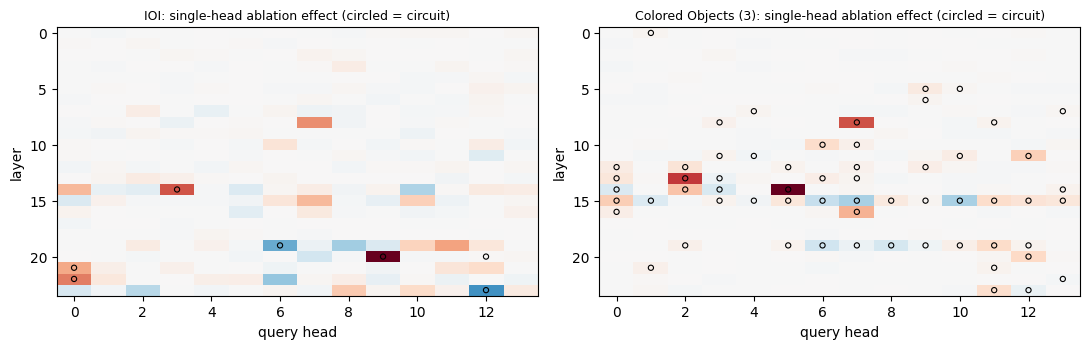

In [11]:
OVER = {}
for m, A in ALL.items():
    d_i, d_c = A["DISC"]["ioi"], A["DISC"]["co"]
    n_heads = d_i["E"].size
    enc = lambda hs: [l * d_i["E"].shape[1] + h for l, h in hs]
    o_all = overlap_stats(enc(d_i["circuit"]), enc(d_c["circuit"]), n_heads)
    o_mov = overlap_stats(enc(d_i["movers"]), enc(d_c["movers"]), n_heads)
    outs_i = [h for v in d_i["outputs"].values() for h in v]; outs_c = [h for v in d_c["outputs"].values() for h in v]
    o_out = overlap_stats(enc(outs_i), enc(outs_c), n_heads)
    shared = sorted(set(d_i["circuit"]) & set(d_c["circuit"]))
    same_role = sum(d_i["roles"][h] == d_c["roles"][h] for h in shared)
    OVER[m] = dict(circuits=o_all, movers=o_mov, output_heads=o_out, shared=[f"{l}.{h}" for l, h in shared], same_role=same_role)
    print(f"\n===== {m} =====")
    print(f"IOI circuit {len(d_i['circuit'])} heads (faith {d_i['faith']:.2f}); CO-3 circuit {len(d_c['circuit'])} heads (faith {d_c['faith']:.2f})")
    print(f"shared heads {o_all['shared']} ({o_all['shared'] / max(1, len(d_i['circuit'])):.0%} of IOI's), Jaccard {o_all['jaccard']:.2f} "
          f"vs chance {o_all['null_mean']:.2f} (p {o_all['p']:.3f}); same role in both: {same_role}/{len(shared)}")
    print(f"movers: IOI {len(d_i['movers'])}, CO {len(d_c['movers'])}, shared {o_mov['shared']}, Jaccard {o_mov['jaccard']:.2f} (p {o_mov['p']:.3f})")
    print(f"all output heads: IOI {len(outs_i)}, CO {len(outs_c)}, shared {o_out['shared']}, Jaccard {o_out['jaccard']:.2f} (p {o_out['p']:.3f})")
    for nm, d in [("IOI", d_i), ("CO-3", d_c)]:
        print(f"  {nm} output heads: " + "; ".join(f"{r}: {', '.join(f'{l}.{h}' for l, h in hs)}" for r, hs in d["outputs"].items()))
    print("shared heads with roles (IOI / CO):", ", ".join(f"{l}.{h} {d_i['roles'][(l, h)]}/{d_c['roles'][(l, h)]}" for l, h in shared))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    for a, (nm, d) in zip(ax, [("IOI", d_i), ("Colored Objects (3)", d_c)]):
        v = np.nanmax(np.abs(d["E"])) or 1
        a.imshow(d["E"], cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
        for (l, h) in d["circuit"]:
            a.scatter(h, l, s=14, facecolors="none", edgecolors="k", linewidths=0.8)
        a.set_title(f"{nm}: single-head ablation effect (circled = circuit)", fontsize=9); a.set_xlabel("query head"); a.set_ylabel("layer")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/circuits_{m.split('/')[-1]}.png", dpi=130); plt.show()

## Part B results
Same tables as the GPT-2 follow-up. **T0** adds Colored Objects: accuracy, and the Merullo repair
(Qwen's IOI suppressors and negative movers forced onto the wrong colours).

In [12]:
def t0_table(R):
    for name in ["co/2", "co/3"]:
        r = R.get(name)
        if not r:
            continue
        f = r.get("force", {})
        arms = "; ".join(f"{g} onto wrong colours -> {f[g + ' onto other']['acc']:.2f}, onto answer -> {f[g + ' onto ref']['acc']:.2f}"
                         for g in ["inhibition", "direct suppressor", "neg mover"] if g + " onto other" in f)
        print(f"{name}: acc {r['acc']:.2f} [{r['acc_ci'][0]:.2f},{r['acc_ci'][1]:.2f}] (chance {r['chance']:.2f})\n   forced attention: {arms or '-'}")


def t1_table(R):
    rows = {}
    print(f"{'task':12s} {'base':>14s} {'flip':>14s} {'no-repeat':>14s} {'flip acc':>8s}  suppressor attn to cands (base/flip/no-rep)  verdict")
    for task in EXCL:
        b, f, n = R.get(f"{task}/base"), R.get(f"{task}/flip"), R.get(f"{task}/norep")
        if not b:
            continue
        gsupp = "inhibition" if "inhibition" in b["attn"] else "direct suppressor"
        ia = lambda r: (r["attn"][gsupp]["ref"] + r["attn"][gsupp]["other"]) if (r and gsupp in r["attn"]) else np.nan
        ok = b["ref_pref"] >= 0.5
        collapse = 1 - n["ref_pref"] / b["ref_pref"] if (n and ok) else np.nan
        drop = (b["ref_pref"] - f["ref_pref"]) / b["ref_pref"] if (f and ok) else np.nan     # signed: >0 means the flip lowered it
        v = [] if ok else ["base ref-pref < 0.5: ratios uninformative"]
        if ok:
            v.append(f"no-repeat collapse {collapse:.0%}")
            if f and EXCL[task]["flip"] is None:
                v.append(f"flip lowers ref-pref by {drop:.0%} ({'relation ignored' if drop < TH['flip_drop'] else 'relation read'})")
        if f and EXCL[task]["flip"] == "x":
            v.append(f"flip acc {f['acc']:.2f} ({'follows repeat' if f['acc'] < 0.5 else 'follows relation'})")
        rows[task] = dict(collapse=collapse, flip_drop=drop, flip_acc=f["acc"] if f and EXCL[task]["flip"] == "x" else np.nan, ok=ok)
        fmt = lambda r: f"{r['ref_pref']:+6.2f} p{r['p_ref']:.2f}" if r else "-"
        fa = f"{f['acc']:.2f}" if f and not np.isnan(f["acc"]) else "-"
        print(f"{task:12s} {fmt(b):>14s} {fmt(f):>14s} {fmt(n):>14s} {fa:>8s}  {ia(b):.2f} / {ia(f):.2f} / {ia(n):.2f}{'':14s} {'; '.join(v)}")
    return rows


def t2_table(R):
    rows = {}
    print(f"{'task':12s} {'base':>6s} {'double':>7s} {'triple':>7s}  agreement on triple: fewest / not-subject")
    for task in EXCL:
        b, d, t = R.get(f"{task}/base"), R.get(f"{task}/double"), R.get(f"{task}/triple")
        if b and d and t:
            fw = t["heur"].get("fewest mentions", {}).get("agree", np.nan)
            ns = t["heur"].get("not the query subject", {}).get("agree", np.nan)
            rows[task] = dict(base=b["acc"], double=d["acc"], triple=t["acc"], fewest=fw)
            print(f"{task:12s} {b['acc']:6.2f} {d['acc']:7.2f} {t['acc']:7.2f}  {fw:20.2f} / {ns:.2f}")
    return rows


def t3_table(R):
    rows = {}
    print(f"{'condition':24s} {'acc':>5s} {'adjacent':>9s} {'two-step':>9s} {'gap':>6s}  picks fewest on adjacent")
    for name, r in R.items():
        if r["kind"] == "chain":
            gap = r["acc_two-step"] - r["acc_adjacent"]
            rows[name] = dict(acc=r["acc"], adjacent=r["acc_adjacent"], two_step=r["acc_two-step"], gap=gap)
            print(f"{name:24s} {r['acc']:5.2f} {r['acc_adjacent']:9.2f} {r['acc_two-step']:9.2f} {gap:+6.2f}  {r['pick_fewest_adjacent']:.2f}")
    return rows


def t4_table(R):
    rows = {}
    print(f"{'condition':34s} {'acc':>5s} {'95% CI':>13s} {'full':>5s}")
    for name, r in R.items():
        if r["kind"] == "relonly":
            rows[name] = dict(acc=r["acc"], full=r["full"])
            print(f"{name:34s} {r['acc']:5.2f} [{r['acc_ci'][0]:.2f},{r['acc_ci'][1]:.2f}] {r['full']:5.2f}")
    return rows


def t5_table(R, groups):
    gs = list(groups)
    print(f"{'condition':30s} " + " ".join(f"{g[:13]:>18s}" for g in gs) + "    (drop in ref-pref: mean / resample; * beyond random)")
    for name, r in R.items():
        cells = []
        for g in gs:
            e = r["ablate"][g]
            cells.append(f"{e['mean']:+5.2f}{'*' if e.get('beyond_random') else ' '}/ {e['resample']:+5.2f}".rjust(18))
        print(f"{name:30s} " + " ".join(cells))
    arms = sorted({a for r in R.values() for a in r.get("force", {})})
    print("\nForced attention (change in ref-pref):")
    print(f"{'condition':30s} " + " ".join(f"{a[:20]:>21s}" for a in arms) + f" {'mover copy (base)':>18s}")
    for name, r in R.items():
        if "force" in r:
            mc = f"{r['mover_copy']['rate']:.2f} ({r['mover_copy']['base']:.2f})" if "mover_copy" in r else "-"
            print(f"{name:30s} " + " ".join(f"{r['force'][a]['d_ref']:+21.2f}" if a in r["force"] else f"{'-':>21s}" for a in arms) + f" {mc:>18s}")


def t6_table(S):
    if "ioi/base" not in S:
        return {}
    n = S["ioi/base"].size
    enc = lambda E: [int(i) for i in np.argsort(-np.abs(E).ravel())[:TOPK_OVERLAP]]
    rows = {}
    print(f"{'condition':20s} {'top-15 Jaccard vs IOI':>22s} {'p':>6s} {'vs CO-3':>9s} {'p':>6s}")
    for name, E in S.items():
        oi = overlap_stats(enc(E), enc(S["ioi/base"]), n)
        oc = overlap_stats(enc(E), enc(S["co/3"]), n) if "co/3" in S else dict(jaccard=np.nan, p=np.nan)
        rows[name] = dict(j_ioi=oi["jaccard"], p_ioi=oi["p"], j_co=oc["jaccard"], p_co=oc["p"])
        print(f"{name:20s} {oi['jaccard']:22.2f} {oi['p']:6.3f} {oc['jaccard']:9.2f} {oc['p']:6.3f}")
    return rows


TABLES = {}
for m, A in ALL.items():
    R = A["R"]
    if not R:
        continue
    print(f"\n==================== {m} ====================")
    print("\nT0 Colored Objects"); t0_table(R)
    print("\nT1 minimal pairs"); t1 = t1_table(R)
    print("\nT2 DoubleIO / TripleIO analogues"); t2 = t2_table(R)
    print("\nT3 three-entity chains"); t3 = t3_table(R)
    print("\nT4 relation-only with examples"); t4 = t4_table(R)
    print("\nT5 ablations and forced attention"); t5_table(R, A["GROUPS"])
    print("\nT6 per-head map overlap"); t6 = t6_table(A["S"])
    TABLES[m] = dict(t1=t1, t2=t2, t3=t3, t4=t4, t6=t6)


==================== Qwen/Qwen2.5-0.5B ====================

T0 Colored Objects
co/2: acc 0.81 [0.75,0.87] (chance 0.50)
   forced attention: direct suppressor onto wrong colours -> 1.00, onto answer -> 0.00; neg mover onto wrong colours -> 0.99, onto answer -> 0.41
co/3: acc 0.73 [0.66,0.80] (chance 0.33)
   forced attention: direct suppressor onto wrong colours -> 1.00, onto answer -> 0.00; neg mover onto wrong colours -> 0.86, onto answer -> 0.35

T1 minimal pairs
task                   base           flip      no-repeat flip acc  suppressor attn to cands (base/flip/no-rep)  verdict
equality        +1.80 p1.00    +2.78 p1.00    +0.06 p0.53        -  0.26 / 0.28 / 0.06               no-repeat collapse 97%; flip lowers ref-pref by -55% (relation ignored)
inequality      +3.77 p1.00    +4.25 p1.00    +0.54 p0.67        -  0.31 / 0.34 / 0.10               no-repeat collapse 86%; flip lowers ref-pref by -13% (relation ignored)
spatial         +6.12 p1.00    +6.00 p1.00    -0.28 p0.39   

## Claims check (corrected criteria)
| Claim | Supported if |
|---|---|
| C0 circuits found | IOI and CO-3 held-out faithfulness in [0.8, 1.25] and necessity beyond every random set |
| C1 repetition is the trigger | No-repeat twins lose ≥ 70% of base ref-pref in most tasks with a clear base |
| C2 relation ignored | Invalid flips lower ref-pref by < 25% (signed) and valid flips' accuracy < 0.5 |
| C3 query-subject repeat | TripleIO-analogue accuracy ≥ 0.9 in most tasks |
| C4 relation-blind, 3 entities | At the largest shot count, two-step − adjacent ≥ 0.3 and adjacent ≤ chance + 0.1 |
| C5 relation not used, format understood | Relation-only at the largest shot count < chance + 0.2 while full-vocab ≈ accuracy |
| C6 same heads as IOI | Exclusion tasks' top-15 heads overlap IOI's (p < 0.05) more than the sequence baseline's |
| C7 IOI and CO share a circuit | Circuit overlap p < 0.05 |

If C2, C4 and C5 all fail *in the relation-reading direction* (flips lower the preference, adjacent
items are solved, relation-only is solved), Qwen reads the relation; Part B's ablations on those
conditions then show whether it routes the answer through the same groups.

In [13]:
CLAIMS = {}
for m, A in ALL.items():
    if m not in TABLES:
        continue
    T, d = TABLES[m], A["DISC"]
    c = {}
    c["C0 circuits found"] = all(x["solved"] and TH["faith"] <= x["faith"] <= 2 - TH["faith"] + 0.05 and x["necessity"] > max(x["rand_necessity"] or [0]) for x in d.values())
    col = [v["collapse"] for v in T["t1"].values() if v["ok"] and not np.isnan(v["collapse"])]
    c["C1 repetition is the trigger"] = bool(col) and np.mean([x >= TH["norep_collapse"] for x in col]) > 0.5
    inv = [v["flip_drop"] for t, v in T["t1"].items() if EXCL[t]["flip"] is None and not np.isnan(v["flip_drop"])]
    val = [v["flip_acc"] for t, v in T["t1"].items() if EXCL[t]["flip"] == "x" and not np.isnan(v["flip_acc"])]
    c["C2 relation ignored"] = bool(inv) and all(x < TH["flip_drop"] for x in inv) and all(x < 0.5 for x in val)
    tr = [v["triple"] for v in T["t2"].values()]
    c["C3 query-subject repeat"] = bool(tr) and np.mean([x >= TH["triple_hold"] for x in tr]) > 0.5
    smax = max(SHOTS)
    ch = [v for k, v in T["t3"].items() if k.endswith(f"/{smax}-shot")]
    c["C4 relation-blind, 3 entities"] = bool(ch) and all(v["gap"] >= TH["chain_gap"] and v["adjacent"] <= 1 / 3 + 0.1 for v in ch)
    ro = [v for k, v in T["t4"].items() if k.endswith(f"/{smax}-shot")]
    c["C5 relation not used"] = bool(ro) and all(v["acc"] < 0.5 + TH["fewshot_margin"] and abs(v["full"] - v["acc"]) < 0.1 for v in ro)
    t6 = T["t6"]
    base_j = t6.get("REF sequence", {}).get("j_ioi", 0.0)
    ex = [v for k, v in t6.items() if k in ("equality/base", "spatial/base", "set_removal/base")]
    c["C6 same heads as IOI"] = bool(ex) and all(v["p_ioi"] < 0.05 and v["j_ioi"] > base_j for v in ex)
    c["C7 IOI and CO share a circuit"] = OVER[m]["circuits"]["p"] < 0.05
    CLAIMS[m] = c
    print(f"\n===== {m} =====")
    for k, v in c.items():
        print(f"  {k:36s} {'SUPPORTED' if v else 'not supported'}")


===== Qwen/Qwen2.5-0.5B =====
  C0 circuits found                    SUPPORTED
  C1 repetition is the trigger         SUPPORTED
  C2 relation ignored                  not supported
  C3 query-subject repeat              SUPPORTED
  C4 relation-blind, 3 entities        not supported
  C5 relation not used                 SUPPORTED
  C6 same heads as IOI                 SUPPORTED
  C7 IOI and CO share a circuit        SUPPORTED


## Save

In [14]:
def to_jsonable(o):
    if isinstance(o, dict): return {(f"{k[0]}.{k[1]}" if isinstance(k, tuple) else str(k)): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (np.floating, np.integer, np.bool_)): return o.item()
    if isinstance(o, torch.Tensor): return o.tolist()
    return o


for m, A in ALL.items():
    res = dict(model=m, test_mode=TEST_MODE, config=dict(SEED=SEED, N_PER=N_PER, N_DISC=N_DISC, K_GRID=K_GRID,
               FAITH_TARGET=FAITH_TARGET, ROLE=ROLE, TH=TH, transformers=transformers.__version__),
               discovery={k: {kk: vv for kk, vv in v.items()} for k, v in A["DISC"].items()},
               groups={g: [f"{l}.{h}" for l, h in hs] for g, hs in A["GROUPS"].items()},
               overlap=OVER.get(m), results=A["R"], head_maps=A["S"], tables=TABLES.get(m), claims=CLAIMS.get(m),
               minutes=A["minutes"],
               prompts={k: [dict(text=q["text"], candidates=q["out_words"][:4], correct=q.get("correct"), ref=q.get("ref"))
                            for q in c["P"][:10]] for k, c in A["C"].items()})
    fn = f"{OUT_DIR}/results_{m.split('/')[-1]}.json"
    with open(fn, "w") as fh:
        json.dump(to_jsonable(res), fh, indent=1)
    print("saved", fn)
if SAVE_TO_DRIVE:
    from google.colab import drive
    import shutil
    drive.mount("/content/drive")
    shutil.copytree(OUT_DIR, f"/content/drive/MyDrive/{OUT_DIR}", dirs_exist_ok=True)

saved qwen_circuit_results/results_Qwen2.5-0.5B.json


## Notes
1. **Roles are assigned by rules** (thresholds in `ROLE`), not by hand. Read the circuit cards: a head
   labelled "other" with a large effect is worth a closer look, and the faithfulness curve shows how
   much of the behaviour the circuit explains.
2. **Mediation is measured through the movers' attention.** A selector that acts on the movers' values
   or directly on the logits, rather than on where they attend, will be missed or labelled "other".
3. **Colored Objects selectors are labelled from CO's own discovery** ("gatherer" = promoter). IOI's
   suppressors are what the Merullo-style repair forces onto the wrong colours.
4. **KV-group ablation** (removing a shared key/value head) is not done here; all interventions are per
   query head.
5. Everything is one prompt sample and one seed. Treat it as a pilot; fix thresholds, then rerun with a
   new `SEED`.